In [2]:
import os
import random
import sys
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
import torchvision.transforms.functional as TF
from pathlib import Path
from torch import optim
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm

# import wandb
from evaluate import evaluate
from unet import UNet

# from utils.data_loading import BasicDataset, CarvanaDataset
from utils.dice_score import dice_loss, multiclass_dice_coeff

import numpy as np
import matplotlib.pyplot as plt

In [3]:
# from fakeionogramdataset import DoubleGaussIonoDataset
from ionogram_parabola_transfer import IonoDataset

In [4]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

model = UNet(n_channels=1, n_classes=3, bilinear=False)
model.load_state_dict(torch.load('path_to_save_model/'+'checkpoint_epoch_4.pth')['model_state_dict'])
model.eval()
model = model.to(device=device)

In [7]:
from torch.optim import Adam

epochs = 3
batch_size = 5
learning_rate = 5e-4
val_percent = 0.1

weight_decay = 1e-8
momentum = 0.2
gradient_clipping = 1.0
       
# dataset = DoubleGaussIonoDataset('training_data_transparent_doublegauss')
dataset = IonoDataset('../LYJ+UNET+doubleGauss/ionogram_train_set_725.npy')

n_val = int(len(dataset) * val_percent)
n_train = len(dataset) - n_val
train_set, val_set = random_split(dataset, [n_train, n_val], generator=torch.Generator().manual_seed(0))

# 3. Create data loaders
loader_args = dict(batch_size=batch_size, num_workers=20, pin_memory=True) #os.cpu_count()

train_loader = DataLoader(train_set, shuffle=True, **loader_args)
val_loader = DataLoader(val_set, shuffle=True, drop_last=True, **loader_args)



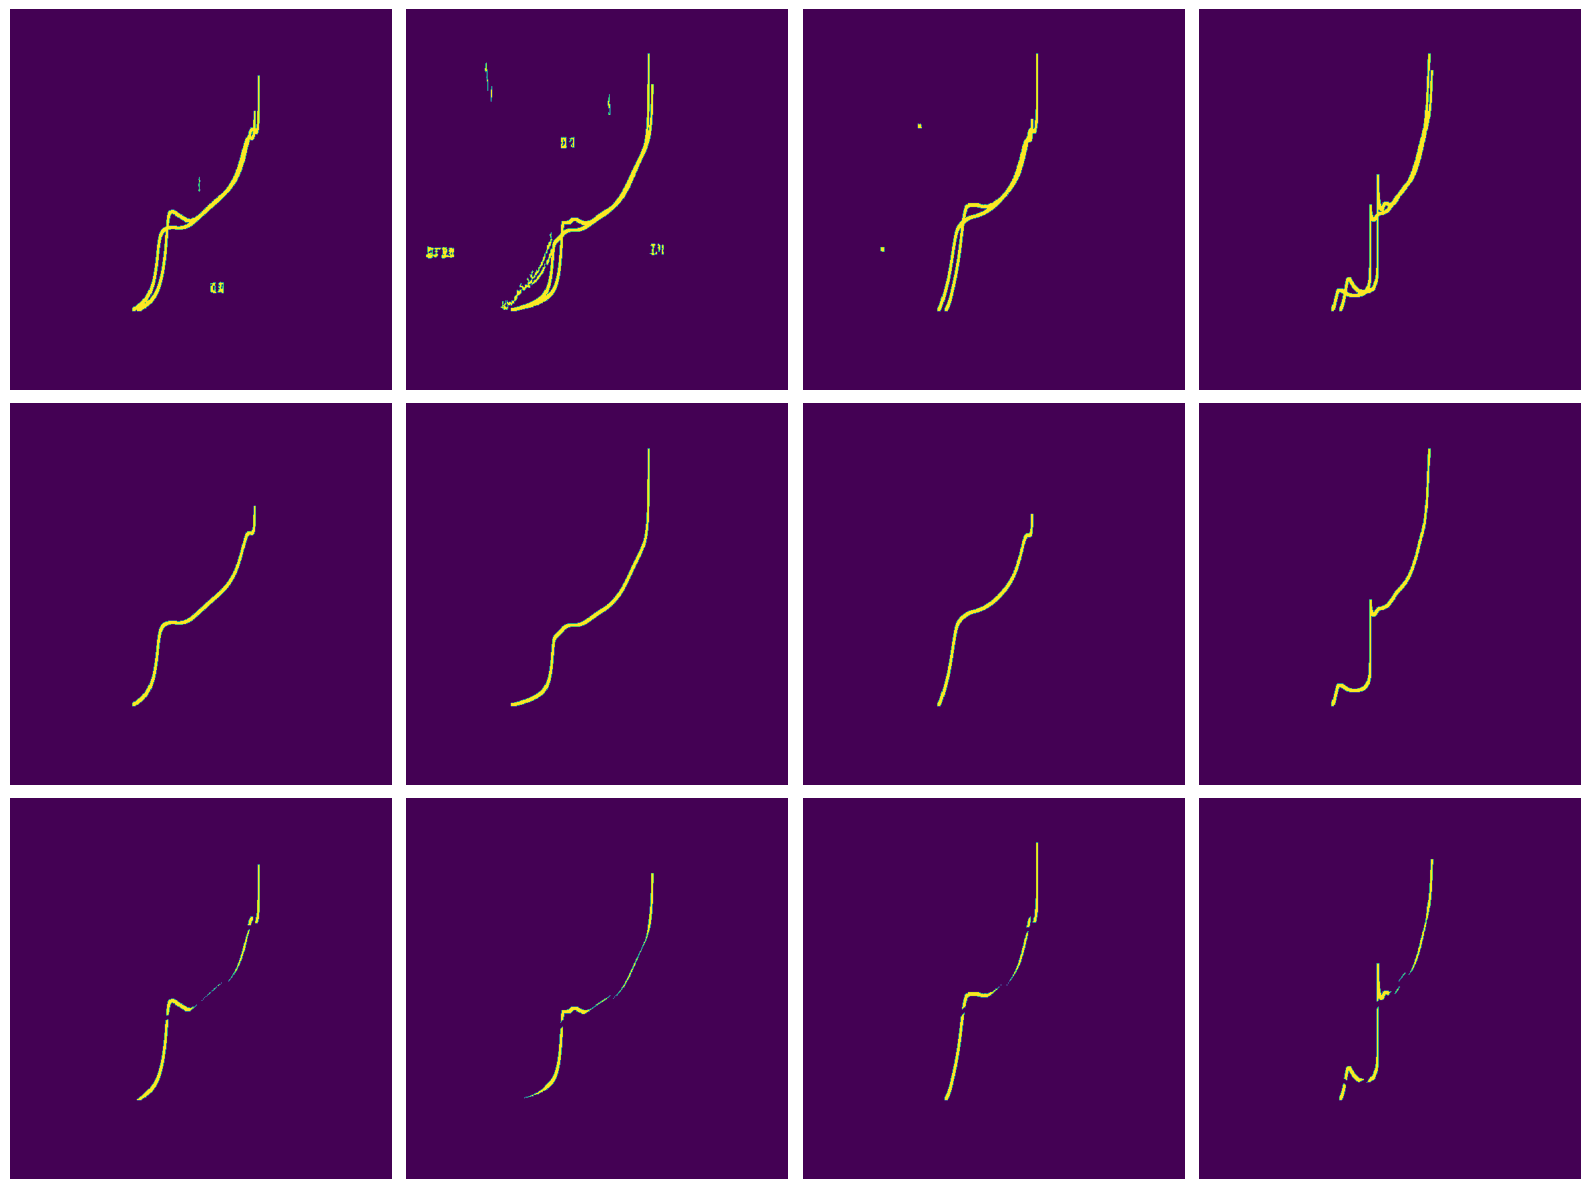

In [9]:
# visualize the training set

fig, axs = plt.subplots(ncols=4, nrows=3, figsize=(16, 12))
for idx, ax_i in enumerate(axs.T):
    target = train_set[idx]
    img = target["image"]
    gt = target["mask"]
#     print(gt.shape)
    ax = ax_i[0]
    img = img.permute((1, 2, 0)).numpy()
    ax.imshow((img * 255).astype(np.uint8), origin = 'lower')
    ax.axis('off')
    ax = ax_i[1]
    gt = gt.squeeze().numpy()
    ax.imshow((gt[0,:,:]*122).astype(np.uint8), origin = 'lower')
    ax.axis('off')
    ax = ax_i[2]
    ax.imshow((gt[1,:,:]*122).astype(np.uint8), origin = 'lower')
    ax.axis('off')
fig.tight_layout()


In [6]:
# find the weight of each class
background = 0
onum = 0
xnum = 0
for idx in range(50):
    target = train_set[idx]
    img = target["image"]
    gt = target["mask"]
    gt = gt.numpy()
    background += np.sum(gt==0)
    onum += np.sum(gt==1)
    xnum += np.sum(gt==2)
# fig.tight_layout()

In [7]:
print(background, onum, xnum)
totalp = background + onum + xnum
print(background/onum,background/xnum)
print(totalp/background,totalp/onum,totalp/xnum)

16173882 77675 107643
208.22506598004506 150.2548423956969
1.0114578553250233 210.61087866108787 151.97644064175097


In [8]:

optimizer = Adam(model.parameters(), lr=learning_rate)
criterion = nn.CrossEntropyLoss(weight = torch.FloatTensor([totalp/background,totalp/onum,totalp/xnum]).to(device))

In [9]:
losses = []
val_losses = []
for epoch in range(epochs):
    model.train()

    with tqdm(total=n_train, desc=f'Epoch {epoch+1}/{epochs}', unit='img') as pbar:
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            inputs, labels = data['image'], data['mask']
            inputs, labels = inputs.to(device), labels.to(device) 
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            pbar.update(inputs.shape[0])
            pbar.set_postfix(**{'loss (batch)': loss.item()})
            
        avg_loss = running_loss / len(train_loader)
        losses.append(avg_loss)
        print(f'Epoch: {epoch + 1}, Loss: {avg_loss:.4f}')
        print('-' * 20)
            
        if not os.path.exists('path_to_save_model'):
            os.makedirs('path_to_save_model')

        torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'loss': loss,
                }, f'path_to_save_model/checkpoint_epoch_transfer_{epoch + 1}.pth')
    
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for i, data in enumerate(val_loader, 0):
                inputs, labels = data['image'], data['mask']
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)                
                loss = criterion(outputs, labels)
                val_loss += loss.item()
            avg_val_loss = val_loss / len(val_loader)
            val_losses.append(avg_val_loss)
            print(f'Validation Loss: {avg_val_loss:.4f}')

#             # randomly select a validation data to plot its predicted vs actual curve
#             rand_index = torch.randint(len(val_loader.dataset), size=(1,)).item()
#             random_data = val_loader.dataset[rand_index]
#             random_input, actual_params = random_data
#             random_input = random_input.to(device).unsqueeze(0)  # add batch dimension and move to device
#             predicted_params = net(random_input).squeeze().cpu().detach().numpy()  # remove batch dimension, move to cpu and convert to numpy
#             actual_params = actual_params.numpy()

#             plot_predicted_vs_actual(predicted_params, actual_params)


Epoch 1/3: 100%|████████████████████████████████████████████████| 552/552 [00:38<00:00, 14.53img/s, loss (batch)=0.0289]

Epoch: 1, Loss: 0.0674
--------------------


Epoch 1/3: 100%|████████████████████████████████████████████████| 552/552 [00:40<00:00, 13.53img/s, loss (batch)=0.0289]


Validation Loss: 0.0587


Epoch 2/3: 100%|████████████████████████████████████████████████| 552/552 [00:37<00:00, 14.54img/s, loss (batch)=0.0274]

Epoch: 2, Loss: 0.0436
--------------------


... (2 outputs left out)

Epoch 3/3: 100%|█████████████████████████████████████████████████| 552/552 [00:38<00:00, 14.51img/s, loss (batch)=0.136]

Epoch: 3, Loss: 0.0345
--------------------


Epoch 3/3: 100%|█████████████████████████████████████████████████| 552/552 [00:39<00:00, 13.81img/s, loss (batch)=0.136]

Validation Loss: 0.0426


In [10]:
ii = 17

torch.Size([1, 1, 572, 572])
torch.Size([3, 572, 572])


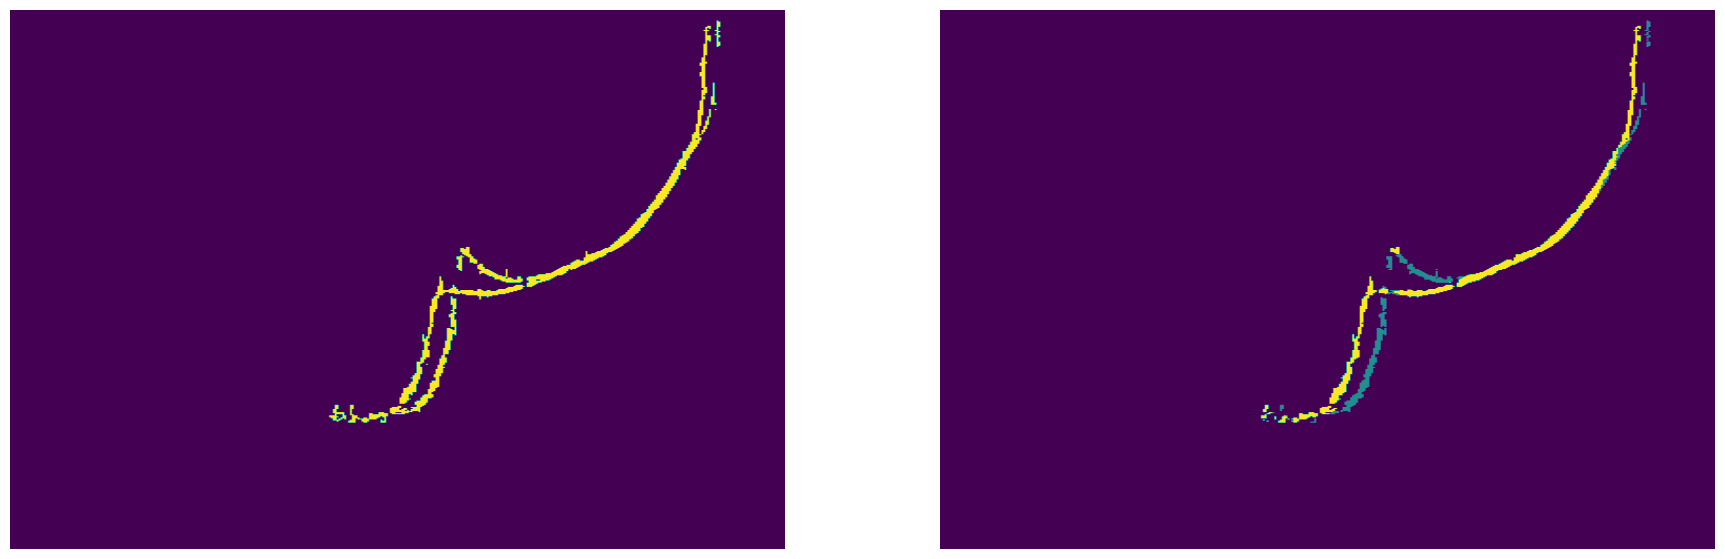

In [99]:
import numpy as np
import matplotlib.pyplot as plt
testing = np.load('ionogram_test_set_177.npy', allow_pickle=True, fix_imports=True)[()]
testdata = testing['all_images']

model.eval()

# testimage1 = torch.from_numpy(testdata[0].astype(np.float32)) 
testimage1 = np.zeros([1,1,572,572],dtype=np.float32)
testimage1[0,0,:512,:408] = testdata[ii]

testimage1 = torch.from_numpy(testimage1) 
# testimage = testimage.repeat(3, 1, 1)
print(testimage1.shape)
testimage1 = testimage1.to('cuda')
label1 = model(testimage1)
label1 = label1.squeeze().to('cpu')
transform = transforms.ToPILImage()
img = transform(label1)
img = np.array(img)

fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(22, 7))

ax = axs[0]
ax.imshow(testdata[ii], origin='lower', aspect = 'auto')
ax.axis('off')
ax = axs[1]
print(label1.shape)
pred = torch.softmax(label1, 0) #.reshape([2,-1])
pred = pred.detach().cpu().numpy()
pred = np.argmax(pred, 0)
ax.imshow(pred[:512,:408], origin='lower', aspect = 'auto')
ax.axis('off')
# fig.tight_layout()
# plt.savefig('testing.png', bbox_inches='tight')
ii += 1